Dataset:
     outlook  temp humidity  windy play
0      sunny   hot     high  False   no
1      sunny   hot     high   True   no
2   overcast   hot     high  False  yes
3      rainy  mild     high  False  yes
4      rainy  cool   normal  False  yes
5      rainy  cool   normal   True   no
6   overcast  cool   normal   True  yes
7      sunny  mild     high  False   no
8      sunny  cool   normal  False  yes
9      rainy  mild   normal  False  yes
10     sunny  mild   normal   True  yes
11  overcast  mild     high   True  yes
12  overcast   hot   normal  False  yes
13     rainy  mild     high   True   no

Features:
['outlook', 'temp', 'humidity', 'windy']

Target:
play

Initial Hypothesis:
['ϕ', 'ϕ', 'ϕ', 'ϕ']

After positive example 3:
['overcast', 'hot', 'high', np.False_]

After positive example 4:
['?', '?', 'high', np.False_]

After positive example 5:
['?', '?', '?', np.False_]

After positive example 7:
['?', '?', '?', '?']

After positive example 9:
['?', '?', '?', '?']

After pos

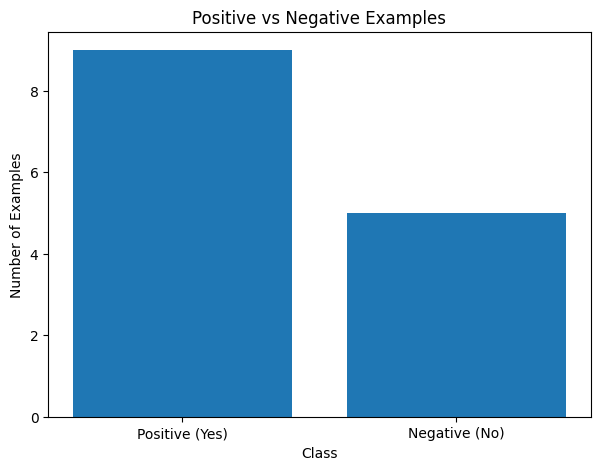

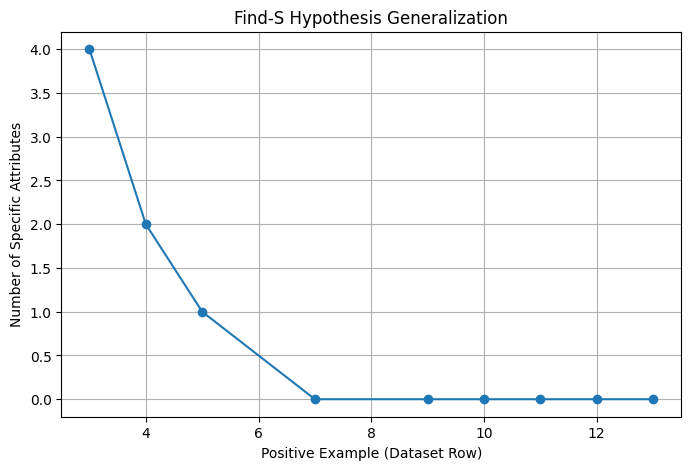

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. READ THE DATASET
# ==========================================

data = pd.read_csv("PlayTennis.csv")

print("Dataset:")
print(data)


# ==========================================
# 2. SEPARATE FEATURES AND TARGET
# ==========================================

target_column = "play"

X = data.drop(columns=[target_column])
y = data[target_column]

features = list(X.columns)

print("\nFeatures:")
print(features)

print("\nTarget:")
print(target_column)


# ==========================================
# 3. FIND-S ALGORITHM
# ==========================================

# Initially, hypothesis is most specific
hypothesis = ["ϕ"] * len(features)

hypothesis_steps = []

print("\nInitial Hypothesis:")
print(hypothesis)

for i in range(len(X)):

    # Find-S considers only positive examples
    if str(y.iloc[i]).lower() == "yes":

        for j in range(len(features)):

            # First positive example
            if hypothesis[j] == "ϕ":
                hypothesis[j] = X.iloc[i, j]

            # If values are different, generalize
            elif hypothesis[j] != X.iloc[i, j]:
                hypothesis[j] = "?"

        # Store hypothesis after this positive example
        hypothesis_steps.append({
            "Dataset Row": i + 1,
            "Hypothesis": str(hypothesis)
        })

        print(f"\nAfter positive example {i + 1}:")
        print(hypothesis)


# ==========================================
# 4. FINAL HYPOTHESIS
# ==========================================

print("\n==========================================")
print("FINAL MOST SPECIFIC HYPOTHESIS")
print("==========================================")

print("<", end="")

for i, value in enumerate(hypothesis):
    print(value, end="")

    if i != len(hypothesis) - 1:
        print(", ", end="")

print(">")


# ==========================================
# 5. GRAPH 1 - POSITIVE VS NEGATIVE
# ==========================================

positive_count = sum(y.str.lower() == "yes")
negative_count = sum(y.str.lower() == "no")

classes = ["Positive (Yes)", "Negative (No)"]
counts = [positive_count, negative_count]

plt.figure(figsize=(7, 5))

plt.bar(classes, counts)

plt.title("Positive vs Negative Examples")
plt.xlabel("Class")
plt.ylabel("Number of Examples")

plt.show()


# ==========================================
# 6. GRAPH 2 - FIND-S GENERALIZATION
# ==========================================

# Calculate number of specific attributes
# '?' means generalized, so it is not specific

positive_rows = []
specific_attributes = []

hypothesis = ["ϕ"] * len(features)

for i in range(len(X)):

    if str(y.iloc[i]).lower() == "yes":

        for j in range(len(features)):

            if hypothesis[j] == "ϕ":
                hypothesis[j] = X.iloc[i, j]

            elif hypothesis[j] != X.iloc[i, j]:
                hypothesis[j] = "?"

        positive_rows.append(i + 1)

        specific_count = 0

        for value in hypothesis:
            if value != "?":
                specific_count += 1

        specific_attributes.append(specific_count)


plt.figure(figsize=(8, 5))

plt.plot(
    positive_rows,
    specific_attributes,
    marker="o"
)

plt.title("Find-S Hypothesis Generalization")
plt.xlabel("Positive Example (Dataset Row)")
plt.ylabel("Number of Specific Attributes")

plt.grid(True)

plt.show()